# Module 3 (step 3) – Feature selection and feature importance per T

Application of **lab 4** (feature selection) to the project, as planned in `MODULES.md` (Module 3, slot 3):
1. **Filter method**: `SelectKBest(mutual_info_classif)` **inside** the pipeline, `k` tuned on the time-based
   validation set.
2. **Embedded method**: L1-penalised logistic regression (lasso), which sets the coefficients of useless
   features to 0. The grid search of notebook 05 selected L1 at every T.
3. **Feature importance per T** for the final model (gradient boosting, chosen by the group): permutation
   importance on the **validation** set.

**Leakage rule:** selection is part of the pipeline, so it is fitted on the training set only. Selecting
features on the whole dataset (train + validation + test) before the split would use the labels of the
validation and test games to choose the features: their scores would be optimistic.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import partial
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from config import *

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
target = pd.read_parquet(PROC_DIR / "target.parquet")
static = pd.read_parquet(PROC_DIR / "features_static.parquet")

NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]

def make_dataset(T):  # same as notebooks 04 and 05
    df = target[["app_id", "release_date", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df.sort_values(["release_date", "app_id"]).reset_index(drop=True)

def make_preprocess(df):
    num = [c for c in NUM_COLS if c in df.columns]
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        remainder="passthrough", verbose_feature_names_out=False)

DATA = {}
for T in T_VALUES:
    df = make_dataset(T)
    tr, va = df[df["split"] == "train"], df[df["split"] == "val"]
    X_cols = [c for c in df.columns if c not in ["app_id", "release_date", "split", "success"]]
    DATA[T] = dict(df=df, Xtr=tr[X_cols], ytr=tr["success"], Xva=va[X_cols], yva=va["success"])

def predefined_split(d):
    X = pd.concat([d["Xtr"], d["Xva"]]); y = pd.concat([d["ytr"], d["yva"]])
    return X, y, PredefinedSplit(np.r_[np.full(len(d["Xtr"]), -1), np.zeros(len(d["Xva"]))])

print({T: DATA[T]["Xtr"].shape[1] for T in T_VALUES}, "raw input columns per T")

{0: 216, 7: 219, 30: 219, 90: 219} raw input columns per T


## 1. Filter method: SelectKBest with mutual information

Mutual information measures how much knowing a feature reduces the uncertainty on the target, including
non-linear relations. `SelectKBest` keeps the `k` best features after preprocessing (one-hot columns
included). `k` is tuned on the validation set, with the tuned logistic regression of notebook 05
(L1, C = 0.1) as classifier.

In [2]:
K_GRID = [10, 20, 40, 80, 150, "all"]
mi = partial(mutual_info_classif, random_state=SEED)
rows, KEPT = [], {}
for T in T_VALUES:
    d = DATA[T]; X, y, ps = predefined_split(d)
    pipe = make_pipeline(make_preprocess(d["df"]), SelectKBest(mi),
                         LogisticRegression(solver="saga", l1_ratio=1, C=0.1, max_iter=3000, random_state=SEED))
    gs = GridSearchCV(pipe, {"selectkbest__k": K_GRID}, scoring="average_precision", cv=ps,
                      refit=False, n_jobs=-1).fit(X, y)
    res = pd.DataFrame(gs.cv_results_)
    for k, s in zip(res["param_selectkbest__k"], res["mean_test_score"]):
        rows.append(dict(T=T, k=str(k), val_pr_auc=s))
    best_k = gs.best_params_["selectkbest__k"]
    fitted = pipe.set_params(selectkbest__k=best_k).fit(d["Xtr"], d["ytr"])
    names = fitted[0].get_feature_names_out()
    KEPT[T] = list(names[fitted[1].get_support()])
    print(f"T={T:>2} best k = {best_k} | validation PR-AUC = {gs.best_score_:.3f} | first kept: {KEPT[T][:8]}")

kbest = pd.DataFrame(rows).pivot(index="k", columns="T", values="val_pr_auc").loc[[str(k) for k in K_GRID]]
kbest.round(3)

T= 0 best k = all | validation PR-AUC = 0.448 | first kept: ['log_price', 'required_age', 'n_languages', 'desc_length', 'release_month_1', 'release_month_2', 'release_month_3', 'release_month_4']


T= 7 best k = all | validation PR-AUC = 0.821 | first kept: ['log_price', 'required_age', 'n_languages', 'desc_length', 'n_reviews', 'pos_ratio', 'release_month_1', 'release_month_2']


T=30 best k = all | validation PR-AUC = 0.862 | first kept: ['log_price', 'required_age', 'n_languages', 'desc_length', 'n_reviews', 'pos_ratio', 'release_month_1', 'release_month_2']


T=90 best k = all | validation PR-AUC = 0.883 | first kept: ['log_price', 'required_age', 'n_languages', 'desc_length', 'n_reviews', 'pos_ratio', 'release_month_1', 'release_month_2']


T,0,7,30,90
k,,,,
10,0.388,0.810,0.854,0.877
20,0.409,0.812,0.854,0.875
40,0.400,0.808,0.853,0.875
80,0.424,0.818,0.857,0.877
150,0.433,0.821,0.861,0.882
all,0.448,0.821,0.862,0.883


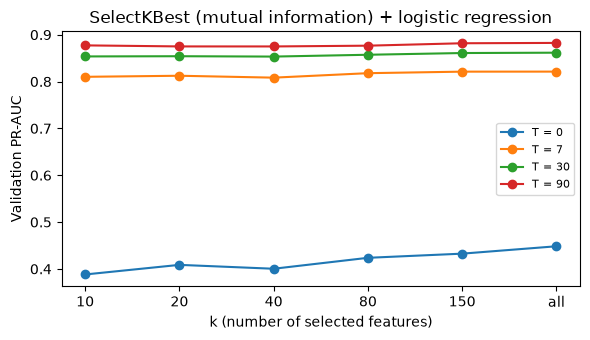

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for T in T_VALUES:
    ax.plot(range(len(K_GRID)), kbest[T], marker="o", label=f"T = {T}")
ax.set_xticks(range(len(K_GRID)), [str(k) for k in K_GRID])
ax.set(xlabel="k (number of selected features)", ylabel="Validation PR-AUC",
       title="SelectKBest (mutual information) + logistic regression")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "selectkbest_k.png", dpi=150); plt.show()

## 2. Embedded method: L1 logistic regression

With an L1 penalty, the logistic regression sets the coefficients of weak features exactly to 0: the
selection is done while fitting. We count the features kept by the tuned model of notebook 05 (L1) at each T.

In [4]:
BEST_C = {0: 0.3, 7: 0.1, 30: 0.1, 90: 0.3}   # grid search of notebook 05 (L1 selected at every T)
l1_rows, L1_COEF = [], {}
for T in T_VALUES:
    d = DATA[T]
    m = make_pipeline(make_preprocess(d["df"]),
                      LogisticRegression(solver="saga", l1_ratio=1, C=BEST_C[T], max_iter=3000, random_state=SEED))
    m.fit(d["Xtr"], d["ytr"])
    coef = pd.Series(m[-1].coef_[0], index=m[0].get_feature_names_out())
    L1_COEF[T] = coef
    l1_rows.append(dict(T=T, n_features=len(coef), n_kept=int((coef != 0).sum()),
                        val_pr_auc=average_precision_score(d["yva"], m.predict_proba(d["Xva"])[:, 1])))
pd.DataFrame(l1_rows).round(3)

,T,n_features,n_kept,val_pr_auc
0,0,233,131,0.456
1,7,236,36,0.821
2,30,236,33,0.862
3,90,236,88,0.885


In [5]:
for T in [0, 30]:
    c = L1_COEF[T][L1_COEF[T] != 0]
    print(f"T={T}: strongest non-zero coefficients")
    print(pd.concat([c.sort_values().head(5), c.sort_values().tail(5)]).round(2).to_string(), "\n")

T=0: strongest non-zero coefficients
tag_Combat             -0.60
tag_Abstract           -0.54
tag_Hidden Object      -0.45
cat_MMO                -0.42
genre_Violent          -0.40
tag_Visual Novel        0.70
tag_Great Soundtrack    0.71
cat_Steam Cloud         0.74
tag_Hentai              1.11
is_free                 1.59 

T=30: strongest non-zero coefficients
tag_Open World              -0.65
tag_Massively Multiplayer   -0.25
tag_Adventure               -0.23
cat_PvP                     -0.18
release_month_3             -0.17
genre_Indie                  0.30
tag_Horror                   0.32
tag_2D                       0.36
pos_ratio                    2.33
n_reviews                    2.93 



**Caution when reading coefficients.** Numerical features are standardised but 0/1 features are not, so
the size of a coefficient is not directly comparable between the two groups. Rare 0/1 features (a tag
present on a few dozen games) can get large, unstable coefficients, and correlated features can even flip
sign (e.g. `win` is almost identical to `in_fronkon`). Coefficients describe associations, not causes.

## 3. Feature importance per T for the final model (gradient boosting)

The group chose **gradient boosting** as the final model (same PR-AUC as stacking in notebook 05, faster
and simpler). Permutation importance: on the **validation** set, we shuffle one input feature at a time and
measure how much the PR-AUC drops (10 repetitions). A large drop means the model relies on that feature.
Hyperparameters: the best configuration found by the random search of notebook 05 at each T.

In [6]:
GB_PARAMS = {   # best configurations of notebook 05 (RandomizedSearchCV on the validation set)
    0:  dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20, l2_regularization=1, max_iter=200, class_weight=None),
    7:  dict(learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1, max_iter=200, class_weight=None),
    30: dict(learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1, max_iter=200, class_weight=None),
    90: dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=50, l2_regularization=0, max_iter=400, class_weight="balanced"),
}
IMP = {}
for T in T_VALUES:
    d = DATA[T]
    gb = make_pipeline(make_preprocess(d["df"]), HistGradientBoostingClassifier(random_state=SEED, **GB_PARAMS[T]))
    gb.fit(d["Xtr"], d["ytr"])
    ap = average_precision_score(d["yva"], gb.predict_proba(d["Xva"])[:, 1])
    pi = permutation_importance(gb, d["Xva"], d["yva"], scoring="average_precision",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    IMP[T] = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std},
                          index=d["Xva"].columns).sort_values("importance", ascending=False)
    print(f"T={T:>2} validation PR-AUC = {ap:.3f} | top 5: {list(IMP[T].index[:5])}")

top = pd.concat({T: IMP[T]["importance"] for T in T_VALUES}, axis=1)
top.loc[top.max(axis=1).sort_values(ascending=False).index[:15]].round(4)

T= 0 validation PR-AUC = 0.486 | top 5: ['n_languages', 'cat_Steam Cloud', 'log_price', 'tag_Singleplayer', 'cat_Steam Achievements']


T= 7 validation PR-AUC = 0.871 | top 5: ['n_reviews', 'pos_ratio', 'cat_Steam Cloud', 'log_price', 'tag_Psychological Horror']


T=30 validation PR-AUC = 0.915 | top 5: ['n_reviews', 'pos_ratio', 'tag_Singleplayer', 'desc_length', 'tag_Horror']


T=90 validation PR-AUC = 0.941 | top 5: ['n_reviews', 'pos_ratio', 'n_languages', 'desc_length', 'release_month']


,0,7,30,90
n_reviews,NaN,0.6605,0.7112,0.7329
pos_ratio,NaN,0.2214,0.2471,0.2860
n_languages,0.0635,0.0014,0.0004,0.0017
cat_Steam Cloud,0.0459,0.0024,-0.0005,0.0007
log_price,0.0443,0.0019,0.0007,0.0008
tag_Singleplayer,0.0229,-0.0012,0.0019,-0.0003
cat_Steam Achievements,0.0187,-0.0025,-0.0001,0.0009
release_month,0.0168,0.0000,0.0002,0.0011
tag_Hentai,0.0151,0.0001,-0.0002,0.0000
mac,0.0135,0.0003,0.0001,0.0004


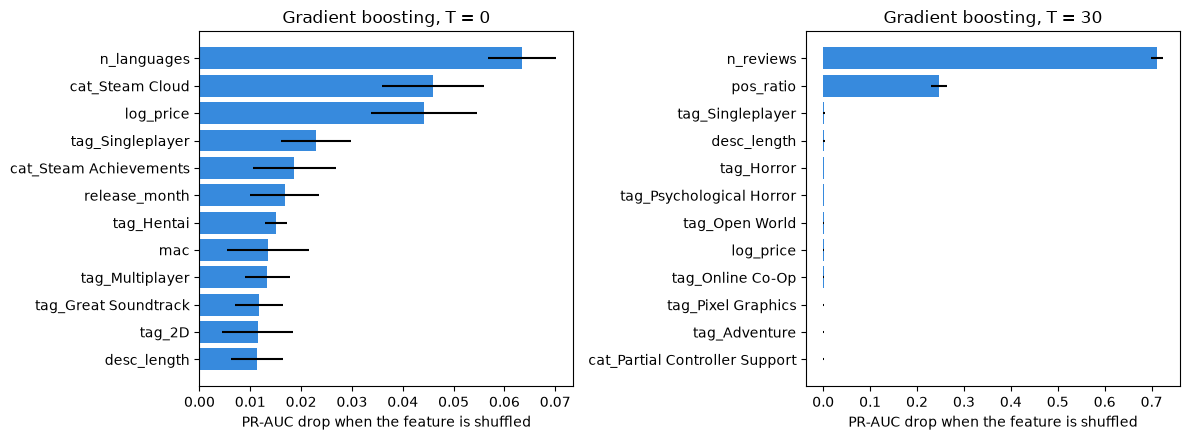

written: report/feature_importance.csv, report/selectkbest_results.csv, report/figures/*.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, T in zip(axes, [0, 30]):
    t = IMP[T].head(12)[::-1]
    ax.barh(t.index, t["importance"], xerr=t["std"], color="#378ADD")
    ax.set(title=f"Gradient boosting, T = {T}", xlabel="PR-AUC drop when the feature is shuffled")
plt.tight_layout(); plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150); plt.show()

top.to_csv(ROOT / "report" / "feature_importance.csv")
kbest.to_csv(ROOT / "report" / "selectkbest_results.csv")
print("written: report/feature_importance.csv, report/selectkbest_results.csv, report/figures/*.png")

**Reading.** At T = 0, only store information is available: the importance is spread over many weak
features. From T = 7, the early reviews (`n_reviews`, `pos_ratio`) dominate. This is consistent with the
jump of the PR-AUC between T = 0 and T = 7, and with the fact that the target is itself defined from the
number and share of positive reviews in the first year.